# 07. Opening / closing

Opening removes small bright details, closing removes small dark ones; the difference to the original (relative to the local background) is the anomaly. Similar to top-hat, with a different response shape.

Method: `filters.py` (`METHOD_NAME = "opening_closing"`). Evaluation: `evaluate.py`, same rules for every experiment (README section 7): threshold from `good_cal` only, false alarms on unseen `good_test` strips and on hard negatives, recall on defect tiles. Per-tile scores and the cal/test split are saved to `results/opening_closing/`.

In [1]:
import sys, importlib

sys.path.insert(0, "../src/methods")
import filters as F    # all filters and methods
import evaluate as E   # shared evaluation (README section 7)
importlib.reload(F); importlib.reload(E)  # pick up edits without restarting the kernel

# ---- evaluation settings (same for every experiment) ----------------------
FABRIC = "02"           # fabric code = third part of the file name
METHOD_NAME = "opening_closing"  # results go to results/<METHOD_NAME>/
THR_K = 4.0             # threshold = median + THR_K x 1.4826 x MAD of good_cal scores
MIN_AREA = 4            # damage mask: drop spots smaller than this (px); keep <= 4
SCORE_K = 25            # tile score = mean of the SCORE_K highest values of the smoothed map
SCORE_SIGMA = 2.0       # smoothing before scoring (px)
NORMALIZE = True        # score = strongest spot / the tile's own typical level (removes strip-to-strip bias)
SETTINGS = dict(thr_k=THR_K, min_area=MIN_AREA, score_k=SCORE_K, score_sigma=SCORE_SIGMA,
                normalize=NORMALIZE)

# ---- method settings -------------------------------------------------------
STEPS = F.DEFAULT_STEPS
KSIZE = 5                 # structuring element size (px)
BG_SIGMA = 15             # local background


def method(tile):
    return F.opening_closing(tile, STEPS, ksize=KSIZE, bg_sigma=BG_SIGMA)


fit = None

## Results for one fabric

In [2]:
res = E.evaluate(method, FABRIC, fit=fit, **SETTINGS)
assert res is not None, f"not enough tiles for fabric {FABRIC}"
S = E.summarize(res)
E.print_summary(res, S)
print("saved to", E.save_results(res, METHOD_NAME))

fabric 02: good_cal 140 tiles (10 strips), good_test 140 tiles (10 strips), 507 hard negatives, 38 defect tiles (0 background tiles skipped)
tile threshold 12.96   pixel threshold 12.96

                    predicted OK   predicted DAMAGED
good + hard neg.             471                 176
defect                        10                  28

false alarm rate    0.7% good_test, 34.5% hard negatives
recall              73.7%  (small <50 px: 65.2% of 23, large: 86.7% of 15)
strip level         false alarm 10.0% of 10 good strips, recall 73.7% of 38 defect strips
precision           13.7%
F1                  0.231
AUROC               0.855   (threshold-free ranking quality)
mean IoU            0.237 over all defect tiles, 0.321 over detected ones
time                2.8 ms/tile (median)
saved to C:\Users\chanupa.d\Documents\concord\fabric inspection\results\opening_closing


### Score distribution and ROC curve
Left: tile scores with the threshold. Right: recall vs false alarm rate for every possible threshold; the dot is the threshold chosen from good_cal. The curve uses test tiles and is for analysis only.

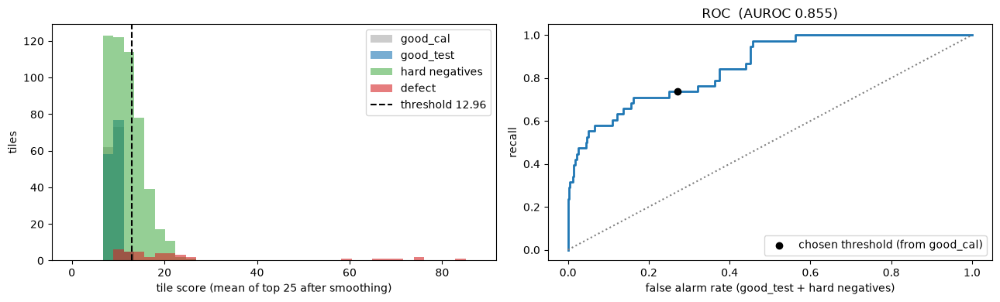

In [3]:
E.plot_scores_roc(res, S)

### Recall per defect type

In [4]:
E.print_by_type(res)

defect   tiles  found   recall  mean IoU  median area  median score
002          1      0       0%      0.00          151         11.96
006          7      7     100%      0.26         1260         71.20
019         23     15      65%      0.25           15         15.60
023          3      2      67%      0.00          778         13.11
030          4      4     100%      0.33           70         23.83


### Failure cases
Missed defects (lowest-scoring defect tiles) and false alarms (highest-scoring good_test / hard-negative tiles). Red = detected, green = ground-truth mask.

10 missed defects, 176 false alarms


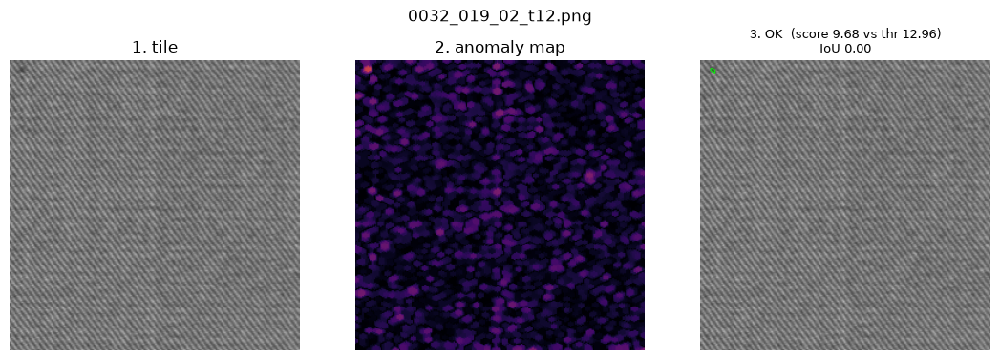

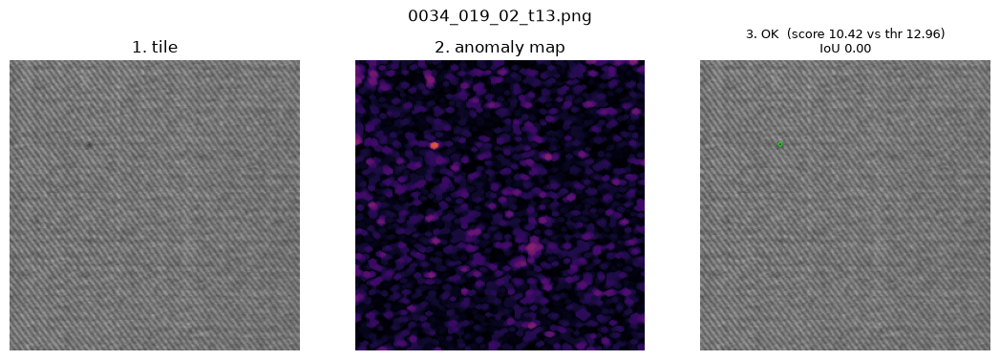

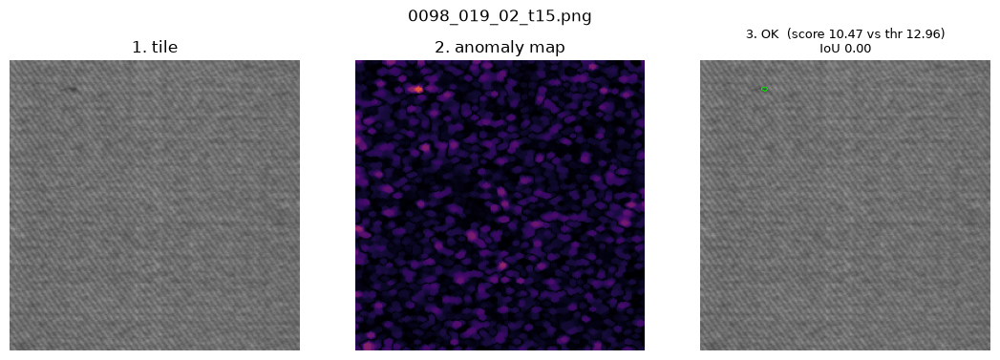

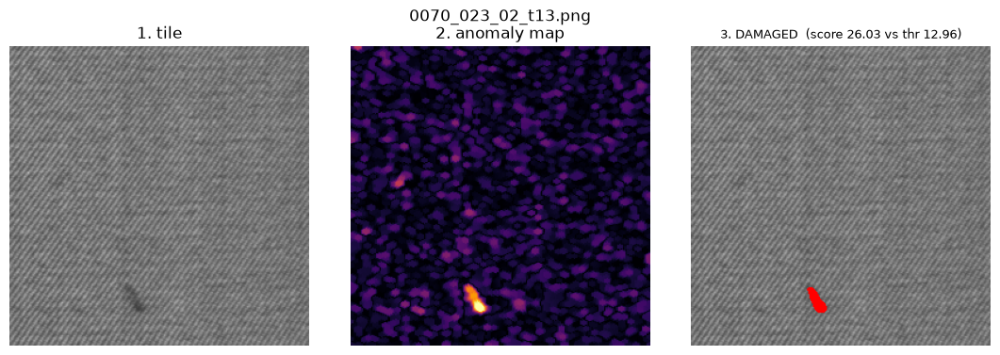

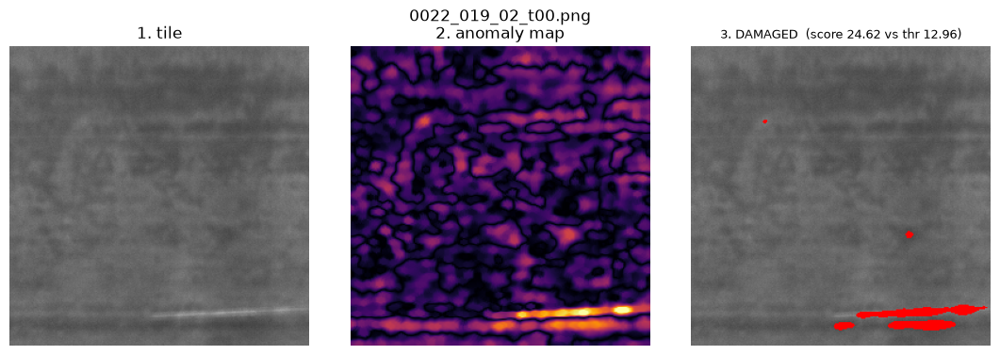

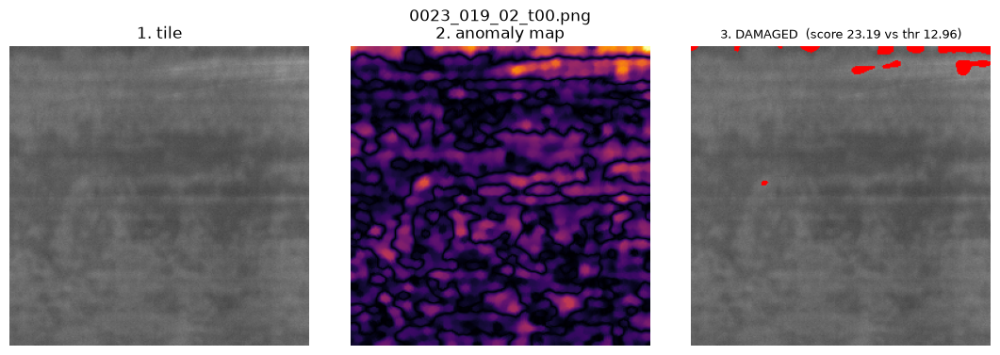

In [5]:
E.show_failures(res, n=3)

### Example tiles
Largest defect, smallest defect (by mask area) and the last good tile of `FABRIC`.

largest defect: 0016_006_02_t12.png, 2111 px


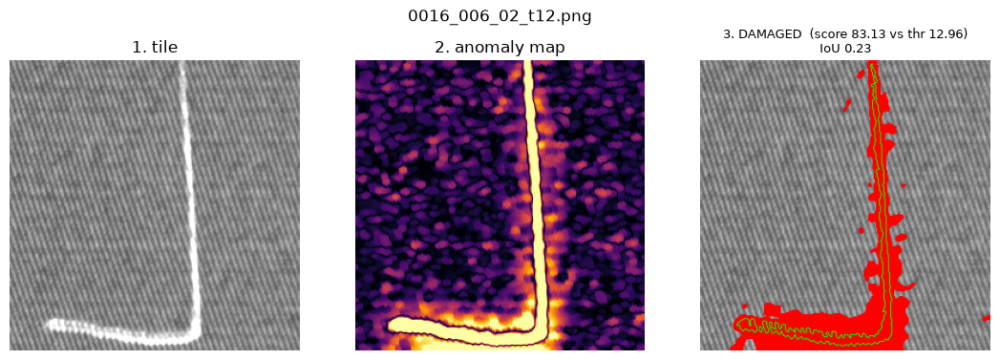

smallest defect: 0025_019_02_t10.png, 8 px


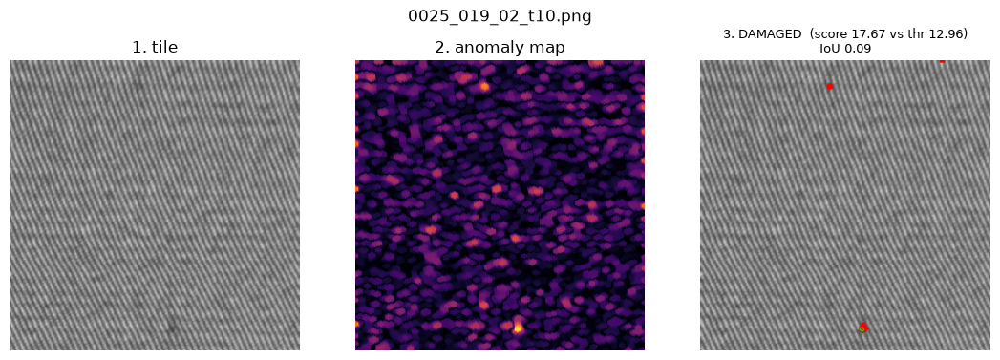

good tile: 0020_000_02_t15.png


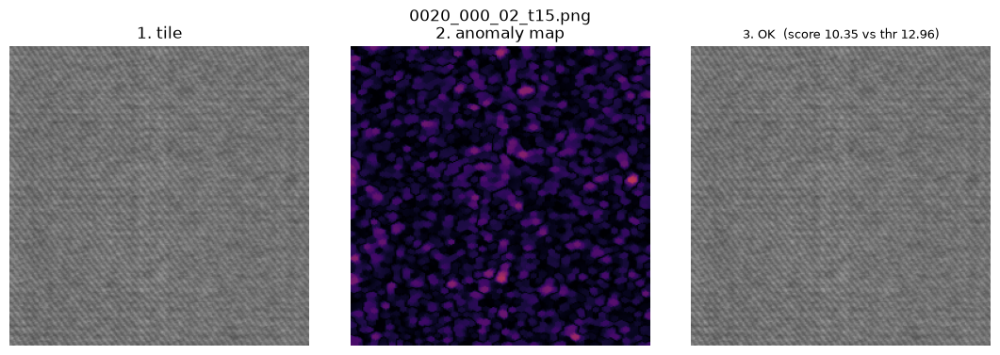

In [6]:
E.show_examples(res)

### One example per defect type
The dataset has 12 defect types (second part of the file name), spread over different fabrics. One tile per type: the clearest one (largest mask) from the fabric with the most tiles of that type. Each is judged with the threshold of its own fabric, set from that fabric's good_cal only (other fabrics are calibrated here, so this cell takes longer). Red = detected, green = ground-truth mask.

type   fabric  tiles  example tile           area px    score      thr  result
002        01     10  0005_002_01_t08.png       2514    14.11    11.76  DAMAGED (caught)
006        02      9  0016_006_02_t12.png       2111    83.13    12.96  DAMAGED (caught)
010        03     63  0103_010_03_t12.png      19060     9.54    14.78  OK (missed)
016        03      7  0021_016_03_t14.png        823    25.59    14.78  DAMAGED (caught)
019        02     40  0023_019_02_t08.png         54    19.86    12.96  DAMAGED (caught)
022        00     12  0065_022_00_t05.png        473     9.85    12.17  OK (missed)
023        01      6  0067_023_01_t09.png        577    10.90    11.76  OK (missed)
025        03      5  0107_025_03_t05.png         24    14.09    14.78  OK (missed)
027        05      1  0094_027_05_t01.png        265    13.00    12.15  DAMAGED (caught)
029        04      2  0083_029_04_t10.png        208    35.77    17.72  DAMAGED (caught)
030        03     14  0076_030_03_t09.png        22

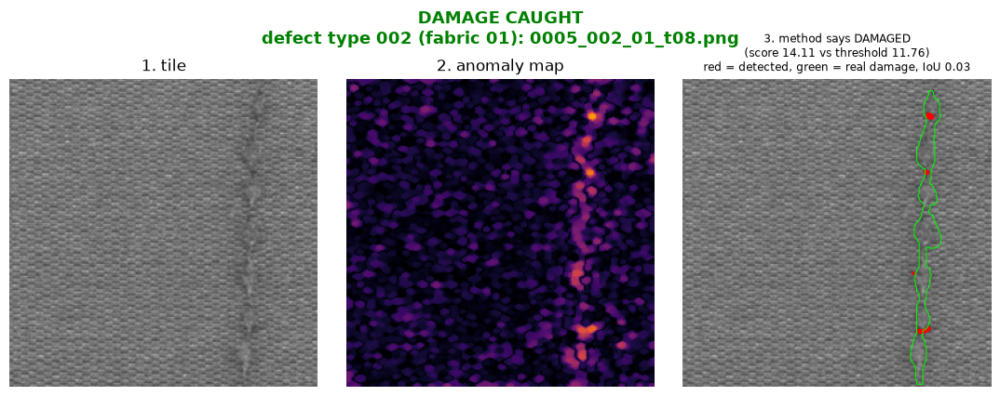

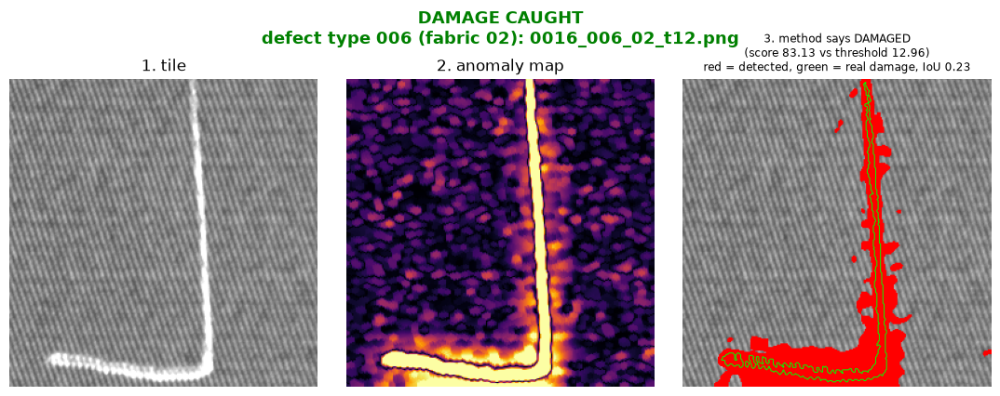

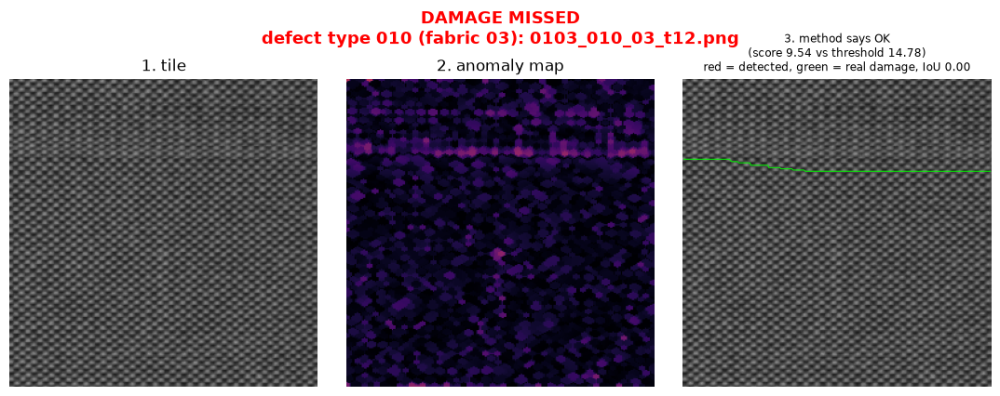

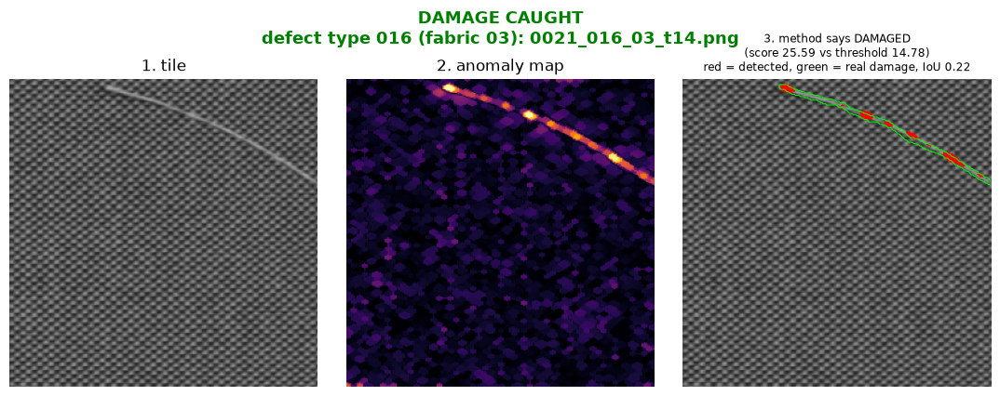

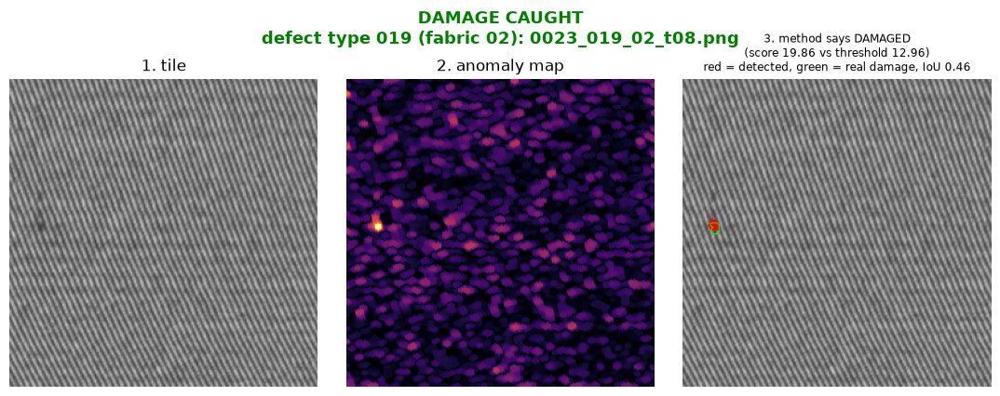

...

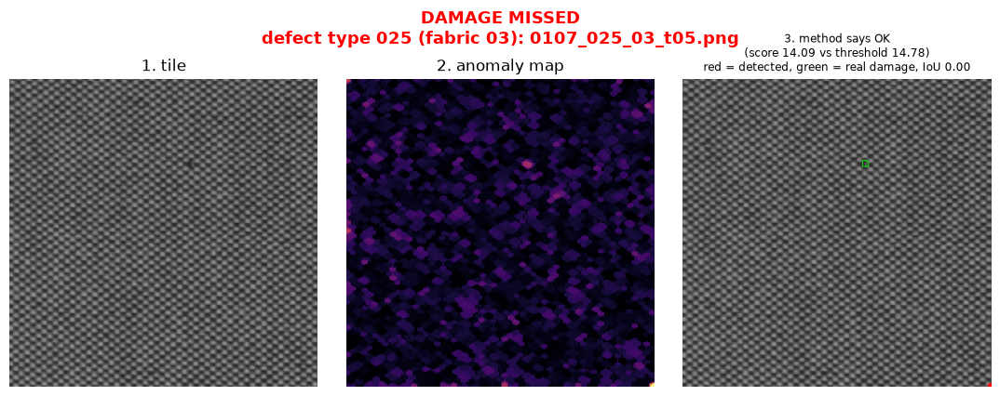

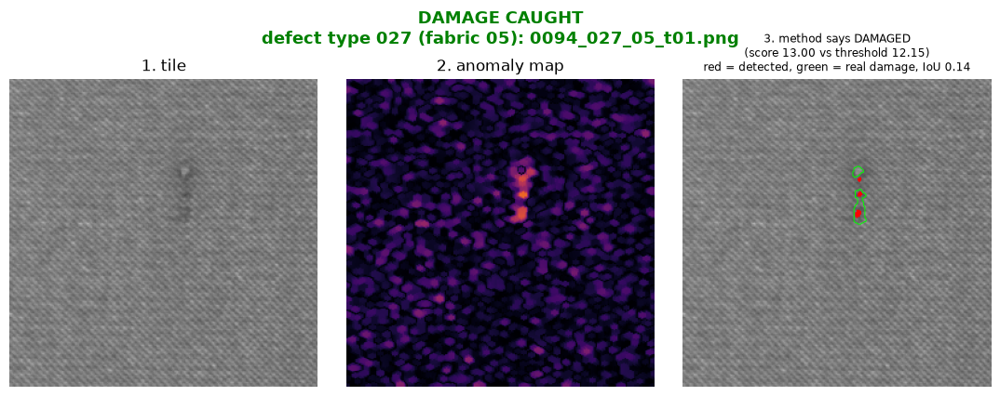

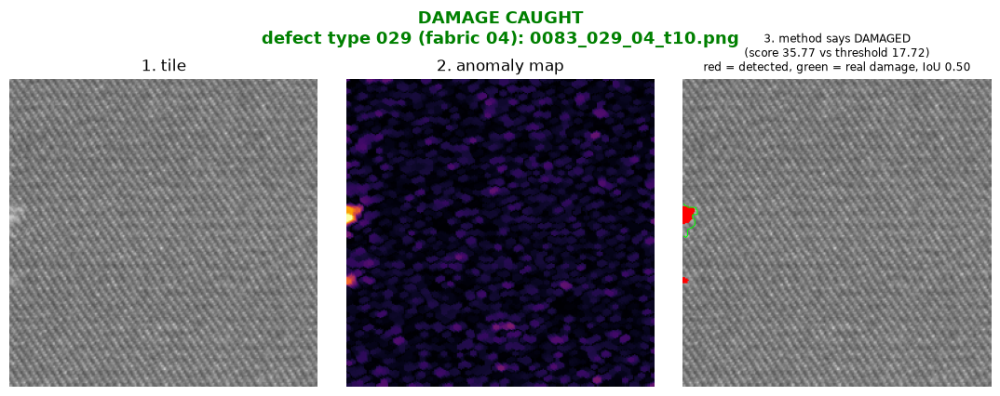

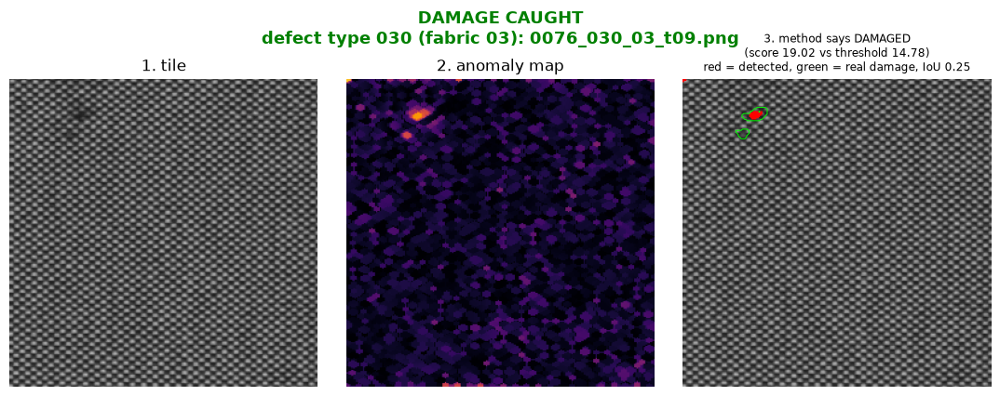

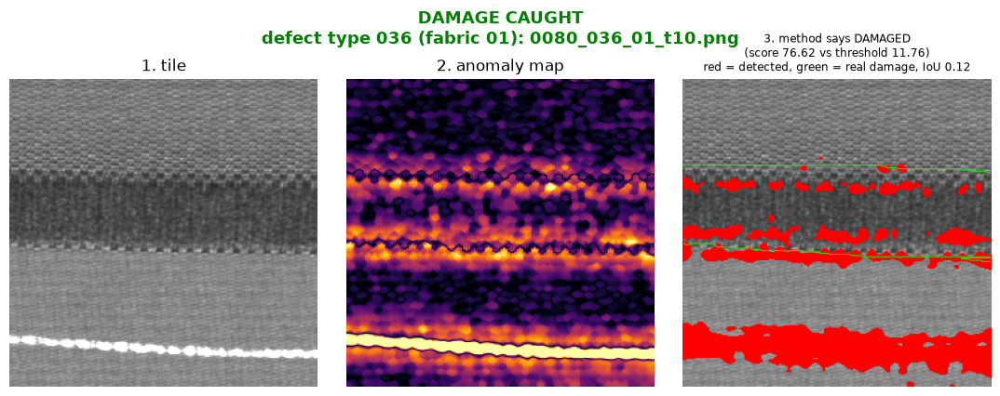

In [4]:
E.show_per_type(method, fit, res, **SETTINGS)

## All fabrics
Same method and settings on every fabric, one threshold per fabric from its own good_cal strips. Columns: FAR on good_test and on hard negatives (hn), recall overall / small / large defects, strip-level FAR and recall, AUROC, IoU, ms per tile.

In [5]:
summaries = E.all_fabrics(method, fit, METHOD_NAME, **SETTINGS)

fabric   test  hard defect    FAR  FAR hn  recall  small  large stripFAR stripRec  AUROC   IoU    ms
----------------------------------------------------------------------------------------------------
00        110    76      9   0.0%    7.9%   66.7% 100.0%  62.5%     0.0%    71.4%  0.897  0.08   2.7
01        154   146     28   1.3%    6.8%   85.7%  50.0%  88.5%    18.2%    83.3%  0.955  0.16   2.1
02        140   507     38   0.7%   34.5%   73.7%  65.2%  86.7%    10.0%    73.7%  0.855  0.24   2.3
03        110   256     89   1.8%    2.0%   31.5%  38.5%  30.3%    20.0%    60.0%  0.766  0.05   1.9
04        138   129     12   5.8%    9.3%   75.0%  80.0%  71.4%    80.0%    80.0%  0.936  0.32   2.2
05        150    13      1   3.3%    0.0%  100.0%    n/a 100.0%    50.0%   100.0%  0.982  0.14   1.9
06        143    81      7   4.9%    6.2%   71.4%  60.0% 100.0%    50.0%    83.3%  0.942  0.13   2.9
-------------------------------------------------------------------------------------------